In [4]:
import math
#import gurobipy as gurobi
import matplotlib.pyplot as plt
#from gurobipy import GRB

### Problem 1: Branch and Bound

Decision variables:

$x \ge 0$, integer: number of tables built
$y = 1$ if the extra machine is rented, else $0$

Objective (maximize profit, in hundreds of dollars):

$$\max z = 7x - 5y$$

Constraints:

$$2x - 5y \le 7 \quad \text{(machine time)}$$

$$2x + y \le 10 \quad \text{(labor)}$$

$$x \ge 0 \text{ and integer}, \quad y \in \{0,1\}$$

LP relaxation: $x \ge 0$ continuous and $0 \le y \le 1$ continuous.

(a) Corner points of the LP relaxation and the feasible region.

Corner points of the LP relaxation:
  (x, y) = (0, 0)   z = 7x - 5y = 0
  (x, y) = (3.5, 0)   z = 7x - 5y = 24.5
  (x, y) = (4.75, 0.5)   z = 7x - 5y = 30.75
  (x, y) = (0, 1)   z = 7x - 5y = -5
  (x, y) = (4.5, 1)   z = 7x - 5y = 26.5

LP optimum: x = 4.75, y = 0.5, z = 30.75


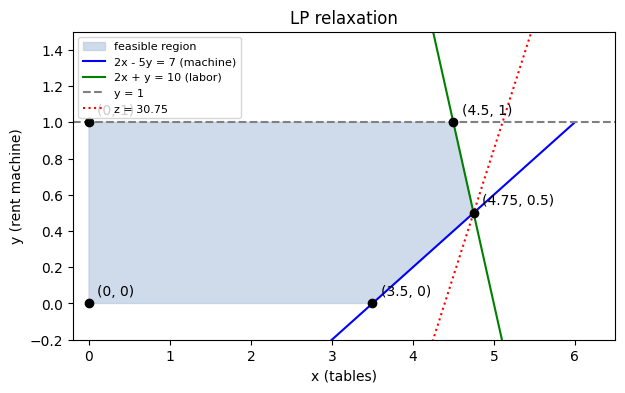

In [6]:
constraints = [
    (2, -5, 7),    # machine time
    (2, 1, 10),    # labor
    (-1, 0, 0),    # x >= 0
    (0, -1, 0),    # y >= 0
    (0, 1, 1),     # y <= 1
]


def feasible(x, y, tol=1e-9):
    return all(a * x + b * y <= c + tol for a, b, c in constraints)


corners = set()
for i in range(len(constraints)):
    for j in range(i + 1, len(constraints)):
        a1, b1, c1 = constraints[i]
        a2, b2, c2 = constraints[j]
        det = a1 * b2 - a2 * b1
        if abs(det) < 1e-12:
            continue
        x = (c1 * b2 - c2 * b1) / det
        y = (a1 * c2 - a2 * c1) / det
        if feasible(x, y):
            corners.add((round(x, 6) + 0.0, round(y, 6) + 0.0))

corners = sorted(corners, key=lambda p: (p[1], p[0]))
print("Corner points of the LP relaxation:")
for (x, y) in corners:
    print(f"  (x, y) = ({x:g}, {y:g})   z = 7x - 5y = {7 * x - 5 * y:g}")
best = max(corners, key=lambda p: 7 * p[0] - 5 * p[1])
print(f"\nLP optimum: x = {best[0]:g}, y = {best[1]:g}, z = {7 * best[0] - 5 * best[1]:g}")

region = [(0, 0), (3.5, 0), (4.75, 0.5), (4.5, 1), (0, 1)]
plt.figure(figsize=(7, 4))
plt.fill([p[0] for p in region], [p[1] for p in region], color="lightsteelblue", alpha=0.6, label="feasible region")
xs = [0, 6]
plt.plot(xs, [(2 * x - 7) / 5 for x in xs], "b-", label="2x - 5y = 7 (machine)")
plt.plot(xs, [10 - 2 * x for x in xs], "g-", label="2x + y = 10 (labor)")
plt.axhline(1, color="gray", ls="--", label="y = 1")
plt.plot(xs, [(7 * x - 30.75) / 5 for x in xs], "r:", label="z = 30.75")
for (x, y) in corners:
    plt.plot(x, y, "ko")
    plt.annotate(f"({x:g}, {y:g})", (x, y), textcoords="offset points", xytext=(6, 6))
plt.xlim(-0.2, 6.5)
plt.ylim(-0.2, 1.5)
plt.xlabel("x (tables)")
plt.ylabel("y (rent machine)")
plt.title("LP relaxation")
plt.legend(loc="upper left", fontsize=8)
plt.savefig("lp_relaxation.png", dpi=200, bbox_inches="tight")
plt.show()

(c) Branch and bound, solving each subproblem as an LP with Gurobi. Rules: LIFO, branch on x if it is
fractional (otherwise y), and solve the x ≥ (or y = 1) child first.

In [ ]:
def solve_lp(x_lb, x_ub, y_lb, y_ub):
    """LP relaxation with branching bounds on x and y. Returns (x, y, z), or None if infeasible."""
    m = gurobi.Model("bb_node")
    m.Params.OutputFlag = 0
    x = m.addVar(lb=x_lb, ub=x_ub, name="x")
    y = m.addVar(lb=y_lb, ub=y_ub, name="y")
    m.setObjective(7 * x - 5 * y, GRB.MAXIMIZE)
    m.addConstr(2 * x - 5 * y <= 7, name="machine")
    m.addConstr(2 * x + y <= 10, name="labor")
    m.optimize()
    if m.Status != GRB.OPTIMAL:
        return None
    return x.X, y.X, m.ObjVal


def is_int(v, tol=1e-6):
    return abs(v - round(v)) < tol


stack = [("root", 0, GRB.INFINITY, 0, 1)]
incumbent, best_z = None, -math.inf
order = 0

while stack:
    desc, x_lb, x_ub, y_lb, y_ub = stack.pop()
    order += 1
    result = solve_lp(x_lb, x_ub, y_lb, y_ub)

    if result is None:
        print(f"Node {order} ({desc}): infeasible -> fathomed")
        continue

    x, y, z = result
    print(f"Node {order} ({desc}): x = {x:g}, y = {y:g}, z = {z:g}", end=" -> ")

    if z <= best_z:
        print(f"fathomed by bound ({z:g} <= incumbent {best_z:g})")
    elif not is_int(x):
        print("branch on x")
        stack.append((f"{desc}, x <= {math.floor(x)}", x_lb, math.floor(x), y_lb, y_ub))
        stack.append((f"{desc}, x >= {math.ceil(x)}", math.ceil(x), x_ub, y_lb, y_ub))
    elif not is_int(y):
        print("branch on y")
        stack.append((f"{desc}, y = 0", x_lb, x_ub, 0, 0))
        stack.append((f"{desc}, y = 1", x_lb, x_ub, 1, 1))
    else:
        print("integer solution, new incumbent -> fathomed")
        incumbent, best_z = (round(x), round(y)), z

print(f"\nOptimal solution: x = {incumbent[0]} tables, y = {incumbent[1]} (rent the machine)")
print(f"Optimal profit: z = {best_z:g} hundred dollars = ${100 * best_z:,.0f}")

Set parameter Username
Set parameter LicenseID to value 2859698
Academic license - for non-commercial use only - expires 2027-09-02
Node 1 (root): x = 4.75, y = 0.5, z = 30.75 -> branch on x
Node 2 (root, x >= 5): infeasible -> fathomed
Node 3 (root, x <= 4): x = 4, y = 0.2, z = 27 -> branch on y
Node 4 (root, x <= 4, y = 1): x = 4, y = 1, z = 23 -> integer solution, new incumbent -> fathomed
Node 5 (root, x <= 4, y = 0): x = 3.5, y = 0, z = 24.5 -> branch on x
Node 6 (root, x <= 4, y = 0, x >= 4): infeasible -> fathomed
Node 7 (root, x <= 4, y = 0, x <= 3): x = 3, y = 0, z = 21 -> fathomed by bound (21 <= incumbent 23)

Optimal solution: x = 4 tables, y = 1 (rent the machine)
Optimal profit: z = 23 hundred dollars = $2,300


### Problem 2: Genetic Algorithm for Cell Tower Placement

**Representation.** A solution is a **chromosome**: a list of 25 genes, one per region, where gene
`j` is 1 if a tower is built in region `j + 1` and 0 otherwise. (Python counts from 0, so position
`j` holds region `j + 1`.)

**Cost.** The GA minimizes

$$\text{cost} = (\text{number of towers}) + \text{penalty} \times (\text{number of uncovered regions}).$$

A region is **covered** if it has a tower, or if one of its adjacent regions has a tower.

In [ ]:
import random
import pandas as pd
import matplotlib.pyplot as plt

adj = pd.read_csv("city_adjacency.csv", index_col=0)   # the first column holds the region labels
A = adj.values                                        # A[i][j] = 1 if regions i+1 and j+1 are adjacent
n = len(A)                                            # 25 regions, so 25 genes per chromosome
print("regions:", n)

regions: 25


---
#### Part 1. Complete the cost and mutation functions

The function `count_uncovered` is provided. Complete `cost` and `mutate`: each says what it should do.
Replace the line `raise NotImplementedError(...)` with your code. Then run the test cell below.

In [ ]:
def count_uncovered(chromosome):
    # PROVIDED. Return the number of regions that are NOT covered by this chromosome.
    # Region i is covered if chromosome[i] == 1, or chromosome[j] == 1 for some j with A[i][j] == 1.
    uncovered = 0
    for i in range(n):
        covered = chromosome[i] == 1 or any(chromosome[j] == 1 and A[i][j] == 1 for j in range(n))
        if not covered:
            uncovered += 1
    return uncovered


def cost(chromosome, penalty):
    # Return (number of towers) + penalty * (number of uncovered regions).
    # The number of towers is the number of genes equal to 1. Use count_uncovered above.
    towers = sum(1 for gene in chromosome if gene == 1)
    return towers + penalty * count_uncovered(chromosome)


def mutate(chromosome, rate, rng):
    # Return a NEW list. For each gene, in order, draw rng.random(); if it is below `rate`,
    # flip the gene (0 becomes 1, 1 becomes 0). Otherwise keep it.
    # Use rng.random(), not random.random(), so that results can be reproduced with a seed.
    child = []
    for gene in chromosome:
        if rng.random() < rate:
            child.append(1 - gene)
        else:
            child.append(gene)
    return child

In [ ]:
# Test cell. Each line prints your result next to the value it should have.
def from_regions(regions):
    # Build a chromosome with towers in the given regions (labels 1 to 25).
    return [1 if (j + 1) in regions else 0 for j in range(n)]

no_towers  = [0] * n
all_towers = [1] * n
seven      = from_regions([1, 3, 10, 12, 13, 21, 24])   # an optimal solution from Assignment 2
six        = from_regions([3, 10, 12, 13, 21, 24])      # the same, without the tower in region 1

print("cost, no towers, penalty 5:   ", cost(no_towers, 5), "  should be 125")
print("cost, seven towers, penalty 5:", cost(seven, 5),     "  should be 7")
print("cost, six towers, penalty 5:  ", cost(six, 5),       "  should be 16")
print("cost, six towers, penalty 1:  ", cost(six, 1),       "  should be 8")

rng = random.Random(0)
print("mutate all towers, rate 0.5:", mutate(all_towers, 0.5, rng)[:8], "  should start [1, 1, 0, 0, 1, 0, 1, 0]")

cost, no towers, penalty 5:    125   should be 125
cost, seven towers, penalty 5: 7   should be 7
cost, six towers, penalty 5:   16   should be 16
cost, six towers, penalty 1:   8   should be 8
mutate all towers, rate 0.5: [1, 1, 0, 0, 1, 0, 1, 0]   should start [1, 1, 0, 0, 1, 0, 1, 0]


---
#### Part 2. The genetic algorithm (provided)

Read through these functions; you do not need to change them. They follow the steps from lecture
(population, selection, crossover, mutation, new generation), with these specific choices:

- **Initial population.** Each gene of each chromosome is 1 with probability `p_one`.
- **Selection (tournament of 2).** To choose a parent, pick two chromosomes at random and keep the
  one with lower cost. This makes fitter chromosomes more likely to become parents: a good
  chromosome wins most of the tournaments it enters, while a poor one rarely does.
- **Crossover (one point).** Pick a cut point `k` at random; child 1 takes genes `0` to `k - 1` from
  parent A and the rest from parent B, and child 2 the reverse.
- **Mutation.** Your `mutate` function, applied to every child.
- **Keeping the best.** The best chromosome found so far is copied unchanged into each new
  generation, so it is never lost. The rest of the new generation consists of children.
- **Stopping rule.** A fixed number of generations.

In [ ]:
def random_population(size, p_one, rng):
    return [[1 if rng.random() < p_one else 0 for _ in range(n)] for _ in range(size)]


def tournament_select(population, penalty, rng):
    a, b = rng.sample(population, 2)
    return a if cost(a, penalty) <= cost(b, penalty) else b


def one_point_crossover(parent_a, parent_b, rng):
    k = rng.randint(1, n - 1)
    return parent_a[:k] + parent_b[k:], parent_b[:k] + parent_a[k:]


def genetic_algorithm(penalty, mutation_rate=1 / 25, pop_size=30, generations=100,
                      p_one=0.3, seed=0):
    rng = random.Random(seed)
    population = random_population(pop_size, p_one, rng)
    best = min(population, key=lambda c: cost(c, penalty))
    history = [cost(best, penalty)]                      # best cost after each generation

    for _ in range(generations):
        new_population = [list(best)]                    # keep the best
        while len(new_population) < pop_size:
            parent_a = tournament_select(population, penalty, rng)
            parent_b = tournament_select(population, penalty, rng)
            for child in one_point_crossover(parent_a, parent_b, rng):
                child = mutate(child, mutation_rate, rng)
                if len(new_population) < pop_size:
                    new_population.append(child)
        population = new_population

        candidate = min(population, key=lambda c: cost(c, penalty))
        if cost(candidate, penalty) < cost(best, penalty):
            best = candidate
        history.append(cost(best, penalty))

    return best, history


def describe(chromosome):
    towers = [j + 1 for j in range(n) if chromosome[j] == 1]
    return {"towers": len(towers), "uncovered": count_uncovered(chromosome), "regions": towers}


def plot_history(history, title):
    plt.figure(figsize=(8, 3.5))
    plt.plot(history)
    plt.xlabel("generation")
    plt.ylabel("best cost so far")
    plt.title(title)
    plt.show()

---
#### Part 3. Experiments

Example: one run with penalty 5 and seed 0.

{'towers': 7, 'uncovered': 0, 'regions': [2, 5, 7, 14, 16, 20, 23]}


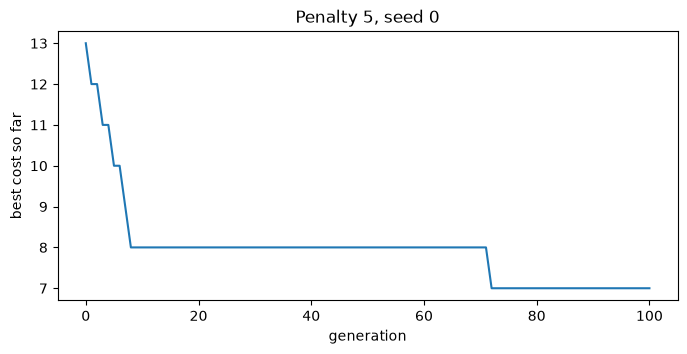

In [ ]:
best, history = genetic_algorithm(penalty=5, seed=0)
print(describe(best))
plot_history(history, "Penalty 5, seed 0")

Use the cells below for parts (b) and (c) of Problem 2. A helper that runs seeds 0 to 9 and
collects the results in a table is provided.

In [ ]:
def run_seeds(penalty, mutation_rate=1 / 25, seeds=range(10)):
    rows = []
    for s in seeds:
        best, _ = genetic_algorithm(penalty=penalty, mutation_rate=mutation_rate, seed=s)
        rows.append({"seed": s, **describe(best)})
    return pd.DataFrame(rows)

# Part (b): run_seeds(5)
# Part (c): run_seeds(5, mutation_rate=0)

(b) Penalty 5, mutation rate 1/25, seeds 0 to 9. An optimal solution has 7 towers and 0 uncovered regions.

In [ ]:
results_b = run_seeds(5)
optimal_b = ((results_b["towers"] == 7) & (results_b["uncovered"] == 0)).sum()
print(f"Runs that found an optimal solution: {optimal_b} of {len(results_b)}")
results_b

Runs that found an optimal solution: 6 of 10


,seed,towers,uncovered,regions
0,0,7,0,"[2, 5, 7, 14, 16, 20, 23]"
1,1,7,0,"[1, 4, 10, 12, 13, 21, 24]"
2,2,7,0,"[3, 6, 10, 13, 16, 20, 23]"
3,3,8,0,"[4, 5, 6, 7, 14, 17, 22, 25]"
4,4,8,0,"[1, 3, 5, 12, 14, 17, 20, 23]"
5,5,7,0,"[3, 6, 10, 13, 18, 21, 25]"
6,6,7,0,"[1, 4, 9, 12, 19, 21, 24]"
7,7,8,0,"[2, 4, 7, 12, 15, 17, 20, 23]"
8,8,7,0,"[3, 6, 10, 14, 17, 20, 24]"
9,9,8,0,"[3, 5, 6, 12, 14, 18, 21, 25]"


(c) Penalty 5, mutation rate 0, seeds 0 to 9.

In [ ]:
results_c = run_seeds(5, mutation_rate=0)
optimal_c = ((results_c["towers"] == 7) & (results_c["uncovered"] == 0)).sum()
print(f"Runs that found an optimal solution: {optimal_c} of {len(results_c)}")
results_c

Runs that found an optimal solution: 0 of 10


,seed,towers,uncovered,regions
0,0,9,0,"[3, 5, 6, 8, 15, 17, 18, 20, 25]"
1,1,9,0,"[1, 4, 8, 10, 11, 16, 19, 20, 23]"
2,2,8,0,"[1, 4, 7, 10, 13, 16, 21, 24]"
3,3,9,0,"[1, 3, 8, 10, 11, 13, 19, 22, 24]"
4,4,8,0,"[3, 5, 6, 8, 17, 19, 22, 25]"
5,5,9,0,"[2, 4, 7, 8, 15, 16, 19, 22, 24]"
6,6,8,0,"[1, 4, 8, 9, 11, 19, 22, 24]"
7,7,8,0,"[2, 4, 6, 10, 13, 17, 20, 23]"
8,8,9,0,"[2, 5, 10, 11, 13, 17, 20, 23, 25]"
9,9,8,0,"[2, 4, 6, 10, 12, 13, 21, 24]"


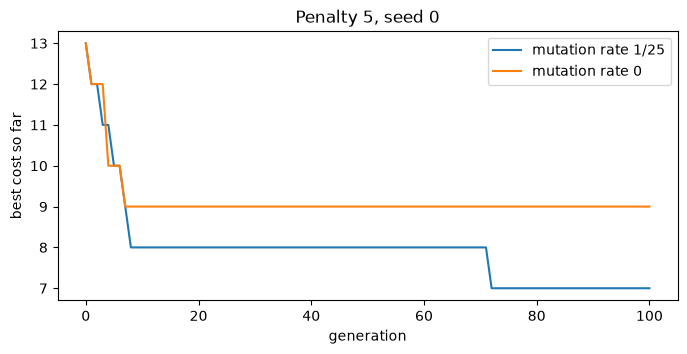

In [ ]:
# Best cost over the generations for seed 0, with and without mutation
_, history_mut = genetic_algorithm(penalty=5, seed=0)
_, history_none = genetic_algorithm(penalty=5, mutation_rate=0, seed=0)
plt.figure(figsize=(8, 3.5))
plt.plot(history_mut, label="mutation rate 1/25")
plt.plot(history_none, label="mutation rate 0")
plt.xlabel("generation")
plt.ylabel("best cost so far")
plt.title("Penalty 5, seed 0")
plt.legend()
plt.show()